In [1]:
%load_ext autoreload
%autoreload 2

%matplotlib widget

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from geodesiq import ControlModel, about

In [2]:
def analytic(x: float, n_plus: float, z0: float, tau: np.ndarray) -> np.ndarray:
    if n_plus == 0:
        return z0 * (1 - 2 * tau)
    elif n_plus == 1:
        return x * np.sinh((1 - 2 * tau) * np.arcsinh(z0 / x))
    elif n_plus == 2:
        return -x * np.tan((2 * tau - 1) * np.arctan(z0 / x))
    elif n_plus == 3:
        return (1 - 2 * tau) * x * z0 / np.sqrt(x ** 2 - 4 * (tau - 1) * tau * z0 ** 2)
    else:
        raise ValueError('No analytical solution available')

In [3]:
def H_fun(x, z):
    return np.array([[z, x], [x, -z]])


def H_partial(x, z):
    return np.array([[1, 0], [0, -1]])


alpha = 1
beta = 1
x = 0.7
z0 = -10

model = ControlModel(H_fun, partial_H_func=H_partial)
model.set_parameters(x=x)
model.set_control(control_name='z', pulse_initial=z0, pulse_final=-z0, initial_state=0, alpha=alpha, beta=beta)
model.solve_problem(pulse_accuracy=int(1e6))

In [5]:
model

------------------ ControlModel Control Summary ------------------
ControlModel: ✅ set
Partial ControlModel: ✅ set
ControlModel parameters: x: 0.7
Control name → z
Pulse initial → -10
Pulse final → 10
Initial state index → 0
Final state index → 0
(Alpha, Beta) → (1, 1)
(Diabatic Alpha, Diabatic Beta) → (❌ not set, ❌ not set)
Eigenproblem solved → ✅ yes
Metric computed → ✅ yes
ODE solved → ✅ yes
---------------------------------------------------------------

In [6]:
model._flags

Flags(
  eigenproblem_solved: stored=True,
  dia_list_computed: stored=True,
  metric_computed: stored=True, parents=['eigenproblem_solved', 'dia_list_computed']
  ode_solved: stored=True, parents=['metric_computed']
)

The average errror is: 8.031648187297455e-09


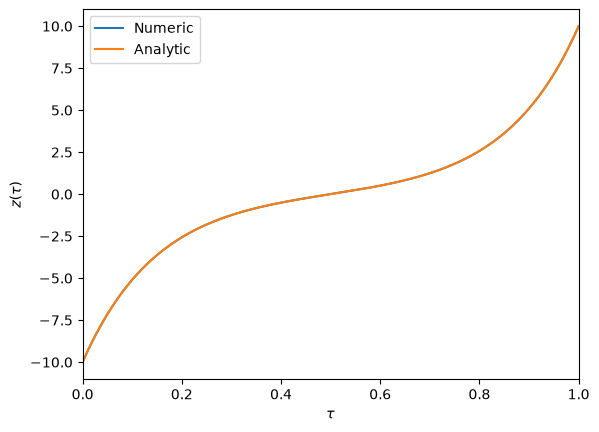

In [4]:
tau, pulse = model.tau, model.control_sol

fig, ax = plt.subplots()
ax.plot(tau, pulse, label='Numeric')

try:
    pulse_an = analytic(x, (alpha + beta) / 2, z0, tau)
    ax.plot(tau, pulse_an, label='Analytic')

    error = np.sum(np.abs(pulse - pulse_an)) / len(tau)
    print(f'The average errror is: {error}')

except ValueError:
    pass

ax.legend()
ax.set_xlabel(r'$\tau$')
ax.set_ylabel(r'$z(\tau)$')
ax.set_xlim(0, 1);

In [ ]:
about()